In [ ]:
#Cleaned_ds_Eff_IBSSA_V7
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.applications.efficientnet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)
from sklearn.preprocessing import label_binarize

In [ ]:
# Loading Cleaned TealeafDataset from Drive

from google.colab import drive
drive.mount('/content/drive')
data_dir = '/content/drive/My Drive/TealeafCleaned dataset'
IMG_SIZE = 384
BATCH_SIZE = 32
SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

Mounted at /content/drive


In [3]:

# 2. Generation of Dataset using imageDataGenerator


datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

generator = datagen.flow_from_directory(
    data_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

class_names = list(generator.class_indices.keys())
num_classes = len(class_names)

print("Classes:", class_names)

Found 6000 images belonging to 6 classes.
Classes: ['Healthy', 'Heliopeltis', 'Red Rust', 'Red Spider', 'Sunlight Scorching', 'Thrips']


In [4]:

# 3. FEATURE EXTRACTION Using EFFICIENTNETV2B3 model

from tensorflow.keras.applications import EfficientNetV2B3
base_model = EfficientNetV2B3(
    weights="imagenet",
    include_top=False,
    pooling="avg",
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

print("Extracting features...")

features = base_model.predict(generator, verbose=1)

labels = generator.classes

print("Feature Shape:", features.shape)


52606240/52606240 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Extracting features...
188/188 ━━━━━━━━━━━━━━━━━━━━ 2578s 14s/step
Feature Shape: (6000, 1536)


In [ ]:
#4 IBSSA
import numpy as np
from scipy.special import gamma
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score


class ImprovedBSSA:

    def __init__(self,
                 n_salps=20,
                 max_iter=20,
                 dim=1408,
                 elite_ratio=0.1,
                 min_features=1,
                 verbose=True):

        print("### Running ImprovedBSSA v2 -- floor=25% of dim, alpha=0.99, 3-fold CV ###")
        self.n_salps = n_salps
        self.max_iter = max_iter
        self.dim = dim
        self.elite_ratio = elite_ratio
        self.min_features = min_features   # safeguard: never return fewer than this many features
        self.verbose = verbose

    # V-shaped transfer function
    def transfer(self, x):
        return np.abs(np.tanh(x))

    # Logistic chaotic initialization
    def chaotic_initialization(self):
        pop = np.zeros((self.n_salps, self.dim))
        for i in range(self.n_salps):
            x = np.random.rand()
            for j in range(self.dim):
                x = 4 * x * (1 - x)
                pop[i, j] = 2 * x - 1
        return pop

    def sigmoid(self, x):
        return 1 / (1 + np.exp(-x))

    def fitness(self, mask, X, y):
        selected_idx = np.where(mask == 1)[0]

       
        floor = max(self.min_features, int(0.25 * self.dim))  # e.g. >=384 of 1536
        if len(selected_idx) < floor:
            return 0.05 * (len(selected_idx) / floor)  # small, scaled penalty

        X_selected = X[:, selected_idx]

        from sklearn.model_selection import cross_val_score
        clf = RandomForestClassifier(n_estimators=50, random_state=42)
        cv_scores = cross_val_score(clf, X_selected, y, cv=3)
        accuracy = cv_scores.mean()

        
        reduction = 1 - (len(selected_idx) - floor) / (self.dim - floor)
        reduction = max(0.0, min(1.0, reduction))

        alpha = 0.99   # accuracy now dominates even more heavily
        fitness = alpha * accuracy + (1 - alpha) * reduction

        return fitness

    # Levy flight
    def levy(self):
        beta = 1.5
        sigma = (
            gamma(1 + beta) * np.sin(np.pi * beta / 2)
            / (gamma((1 + beta) / 2) * beta * 2 ** ((beta - 1) / 2))
        ) ** (1 / beta)

        u = np.random.randn(self.dim) * sigma
        v = np.random.randn(self.dim)
        step = u / (np.abs(v) ** (1 / beta))
        return step

    def _binarize(self, continuous):
        """Stochastic binarization used consistently everywhere a mask is needed."""
        rand = np.random.rand(*continuous.shape) if continuous.ndim > 1 else np.random.rand(self.dim)
        return (self.transfer(continuous) > rand).astype(int)

    def optimize(self, X, y):

        salps = self.chaotic_initialization()

        food_position = np.zeros(self.dim)
        food_mask = None          # FIX: track the actual binary mask, not just the continuous vector
        food_fitness = -np.inf

        stagnation = 0
        elite_size = max(1, int(self.elite_ratio * self.n_salps))

        for iteration in range(self.max_iter):

            # Convert continuous salps to binary mask for fitness evaluation
            binary = self._binarize(salps)

            fitness = np.array([self.fitness(binary[i], X, y) for i in range(self.n_salps)])

            best = np.argmax(fitness)

            if fitness[best] > food_fitness:
                food_fitness = fitness[best]
                food_position = salps[best].copy()
                food_mask = binary[best].copy()      # FIX: store the mask that actually earned this fitness
                stagnation = 0
            else:
                stagnation += 1

            elite_index = np.argsort(fitness)[-elite_size:]
            elites = salps[elite_index].copy()

            c1 = (
                2 * np.exp(-(4 * iteration / self.max_iter) ** 2)
                + 0.3 * (1 - iteration / self.max_iter)
            )

            # Leader
            c2 = np.random.rand(self.dim)
            c3 = np.random.rand(self.dim)
            salps[0] = food_position + c1 * ((2 * c2) - 1)

            # Followers
            for i in range(1, self.n_salps):
                salps[i] = (salps[i] + salps[i - 1]) / 2

            # Opposition-based learning
            opposite = -salps
            opposite_binary = self._binarize(opposite)
            opposite_fit = np.array([self.fitness(opposite_binary[i], X, y) for i in range(self.n_salps)])

            # FIX: also check whether opposition-based search found a new global best
            opp_best = np.argmax(opposite_fit)
            if opposite_fit[opp_best] > food_fitness:
                food_fitness = opposite_fit[opp_best]
                food_position = opposite[opp_best].copy()
                food_mask = opposite_binary[opp_best].copy()
                stagnation = 0

            for i in range(self.n_salps):
                if opposite_fit[i] > fitness[i]:
                    salps[i] = opposite[i]

            # Adaptive mutation
            mutation_rate = 0.1 * (1 - iteration / self.max_iter)
            for i in range(self.n_salps):
                if np.random.rand() < mutation_rate:
                    bit = np.random.randint(self.dim)
                    salps[i, bit] *= -1

            # Levy escape
            if stagnation >= 5:
                salps[0] += 0.02 * self.levy()
                stagnation = 0

            # Elite preservation
            worst = np.argsort(fitness)[:elite_size]
            salps[worst] = elites

            if self.verbose:
                n_sel = int(food_mask.sum()) if food_mask is not None else 0
                print(f"Iter {iteration + 1:>2}/{self.max_iter} | "
                      f"best fitness so far: {food_fitness:.4f} | "
                      f"features selected: {n_sel}/{self.dim}")

        # FIX: return the mask that actually earned the recorded best fitness,
        # instead of re-thresholding food_position with a different (fixed 0.5) rule.
        if food_mask is None or food_mask.sum() == 0:
                     
            freq = self._binarize(salps).sum(axis=0)
            top_idx = np.argsort(freq)[-max(self.min_features, int(0.3 * self.dim)):]
            food_mask = np.zeros(self.dim, dtype=int)
            food_mask[top_idx] = 1
            if self.verbose:
                print("Warning: search collapsed to an empty mask; "
                      f"falling back to top {food_mask.sum()} most frequently "
                      "selected dimensions instead of using all features.")

        return food_mask


In [6]:
# 5. Train/Test split FIRST (raw features), THEN run IBSSA on TRAINING data only
# -- this avoids feature-selection leakage: the test set is never seen by IBSSA

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    features,
    labels,
    test_size=0.2,
    stratify=labels,
    random_state=42
)

print("Running Improved Binary SSA (on TRAINING data only)...")

bssa = ImprovedBSSA(
    n_salps=20,
    max_iter=20,
    dim=features.shape[1],
    elite_ratio=0.1
)

best_mask = bssa.optimize(X_train_raw, y_train)   # <-- test set never touched here

selected_features_indices = np.where(best_mask == 1)[0]
print(f"Selected Features: {len(selected_features_indices)}")

# Apply the SAME mask to both train and test
X_train = X_train_raw[:, selected_features_indices]
X_test = X_test_raw[:, selected_features_indices]

print("X_train shape after feature selection:", X_train.shape)
print("X_test shape after feature selection:", X_test.shape)


Running Improved Binary SSA (on TRAINING data only)...
### Running ImprovedBSSA v2 -- floor=25% of dim, alpha=0.99, 3-fold CV ###
Iter  1/20 | best fitness so far: 0.7843 | features selected: 836/1536
Iter  2/20 | best fitness so far: 0.7848 | features selected: 605/1536
Iter  3/20 | best fitness so far: 0.7848 | features selected: 605/1536
Iter  4/20 | best fitness so far: 0.7848 | features selected: 605/1536
Iter  5/20 | best fitness so far: 0.7848 | features selected: 605/1536
Iter  6/20 | best fitness so far: 0.7873 | features selected: 847/1536
Iter  7/20 | best fitness so far: 0.7873 | features selected: 847/1536
Iter  8/20 | best fitness so far: 0.7873 | features selected: 847/1536
Iter  9/20 | best fitness so far: 0.7873 | features selected: 847/1536
Iter 10/20 | best fitness so far: 0.7873 | features selected: 847/1536
Iter 11/20 | best fitness so far: 0.7873 | features selected: 847/1536
Iter 12/20 | best fitness so far: 0.7873 | features selected: 847/1536
Iter 13/20 | best 

In [7]:
# 6. One-hot encode labels (train/test split already done in the cell above)

y_train_cat = tf.keras.utils.to_categorical(y_train, num_classes)
y_test_cat = tf.keras.utils.to_categorical(y_test, num_classes)


In [8]:
# 7. Split BEFORE augmentation, then augment train and validation
#    INDEPENDENTLY (separate noise draws, no shared samples) --
#    this reproduces the manuscript's reported 7,680 / 1,920 split
#    while eliminating the train/validation leakage.

X_train_core, X_val_core, y_train_core_cat, y_val_core_cat = train_test_split(
    X_train,
    y_train_cat,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print(f"Core training samples (pre-augmentation): {X_train_core.shape[0]}")
print(f"Core validation samples (pre-augmentation): {X_val_core.shape[0]}")

def augment_features_with_noise(features, labels, num_augmentations=1, noise_std=0.01):
    augmented_features = [features]
    augmented_labels = [labels]
    for _ in range(num_augmentations):
        noise = np.random.normal(loc=0.0, scale=noise_std, size=features.shape)
        augmented_features.append(features + noise)
        augmented_labels.append(labels)
    return np.vstack(augmented_features), np.vstack(augmented_labels)

# IMPORTANT: augment train and validation SEPARATELY (independent noise draws).
# Each call only duplicates samples from within its own split -- a validation
# sample's noisy twin can never end up in the training set, and vice versa.
X_train_augmented, y_train_cat_augmented = augment_features_with_noise(
    X_train_core, y_train_core_cat, num_augmentations=1, noise_std=0.01
)

X_val, y_val_cat = augment_features_with_noise(
    X_val_core, y_val_core_cat, num_augmentations=1, noise_std=0.01
)

print(f"Augmented training shape: {X_train_augmented.shape}   (expected: 7680)")
print(f"Augmented validation shape: {X_val.shape}   (expected: 1920)")


Core training samples (pre-augmentation): 3840
Core validation samples (pre-augmentation): 960
Augmented training shape: (7680, 847)   (expected: 7680)
Augmented validation shape: (1920, 847)   (expected: 1920)


In [9]:
# 8. Multi-Layer Perceptron (MLP) for classification -- revised to close the
#    train/val overfitting gap (added missing dropout before output,
#    added BatchNormalization for training stability, slightly reduced
#    layer width to better match the effective training set size)

from tensorflow.keras.layers import BatchNormalization

model = Sequential([

    Dense(
        384,                              # reduced from 512
        activation='relu',
        input_shape=(X_train.shape[1],),
        kernel_regularizer=l2(0.001)
    ),
    BatchNormalization(),
    Dropout(0.4),

    Dense(
        192,                              # reduced from 256
        activation='relu',
        kernel_regularizer=l2(0.001)
    ),
    BatchNormalization(),
    Dropout(0.4),

    Dense(
        96,                               # reduced from 128
        activation='relu',
        kernel_regularizer=l2(0.001)
    ),
    BatchNormalization(),
    Dropout(0.3),                         # <-- the missing dropout, now added

    Dense(
        num_classes,
        activation='softmax'
    )
])

model.compile(
    optimizer=Adam(0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 384)            │       325,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 384)            │         1,536 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 384)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 192)            │        73,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 192)            │           768 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 192)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 96)             │        18,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 96)             │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           582 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,350 (1.61 MB)

 Trainable params: 420,006 (1.60 MB)

 Non-trainable params: 1,344 (5.25 KB)

In [10]:
# 9. Training -- Early Stopping + explicit, leakage-free validation set

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.1,
    patience=5,
    min_lr=0.000001,
    verbose=1
)

history = model.fit(
    X_train_augmented,
    y_train_cat_augmented,
    epochs=50,
    batch_size=32,
    validation_data=(X_val, y_val_cat),
    verbose=1,
    callbacks=[early_stopping, reduce_lr]
)


Epoch 1/50
240/240 ━━━━━━━━━━━━━━━━━━━━ 9s 16ms/step - accuracy: 0.2862 - loss: 2.9625 - val_accuracy: 0.4042 - val_loss: 2.5116 - learning_rate: 1.0000e-04
Epoch 2/50
240/240 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.4046 - loss: 2.5377 - val_accuracy: 0.5193 - val_loss: 2.1703 - learning_rate: 1.0000e-04
Epoch 3/50
240/240 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.4590 - loss: 2.3666 - val_accuracy: 0.5734 - val_loss: 2.0361 - learning_rate: 1.0000e-04
Epoch 4/50
240/240 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.5059 - loss: 2.2279 - val_accuracy: 0.6198 - val_loss: 1.9430 - learning_rate: 1.0000e-04
Epoch 5/50
240/240 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.5574 - loss: 2.1025 - val_accuracy: 0.6328 - val_loss: 1.8696 - learning_rate: 1.0000e-04
Epoch 6/50
240/240 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.5677 - loss: 2.0417 - val_accuracy: 0.6802 - val_loss: 1.7800 - learning_rate: 1.0000e-04
Epoch 7/50
240/240 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - acc

In [11]:

# 10. Execution of Testing data Report


loss, acc = model.evaluate(
    X_test,
    y_test_cat,
    verbose=0
)

print("\nTest Accuracy:", round(acc,2))







Test Accuracy: 0.85


In [12]:


#  11. Model prediction

y_pred_prob = model.predict(X_test)

y_pred = np.argmax(
    y_pred_prob,
    axis=1
)


38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


In [13]:
# 12. Classification Repot Analysis

y_pred_prob = model.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)



print("\nClassification Report\n")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=class_names
    )
)

38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

Classification Report

                    precision    recall  f1-score   support

           Healthy       0.84      0.80      0.82       200
       Heliopeltis       0.87      0.89      0.88       200
          Red Rust       0.87      0.93      0.90       200
        Red Spider       0.84      0.82      0.83       200
Sunlight Scorching       0.79      0.71      0.75       200
            Thrips       0.86      0.94      0.89       200

          accuracy                           0.85      1200
         macro avg       0.85      0.85      0.84      1200
      weighted avg       0.85      0.85      0.84      1200



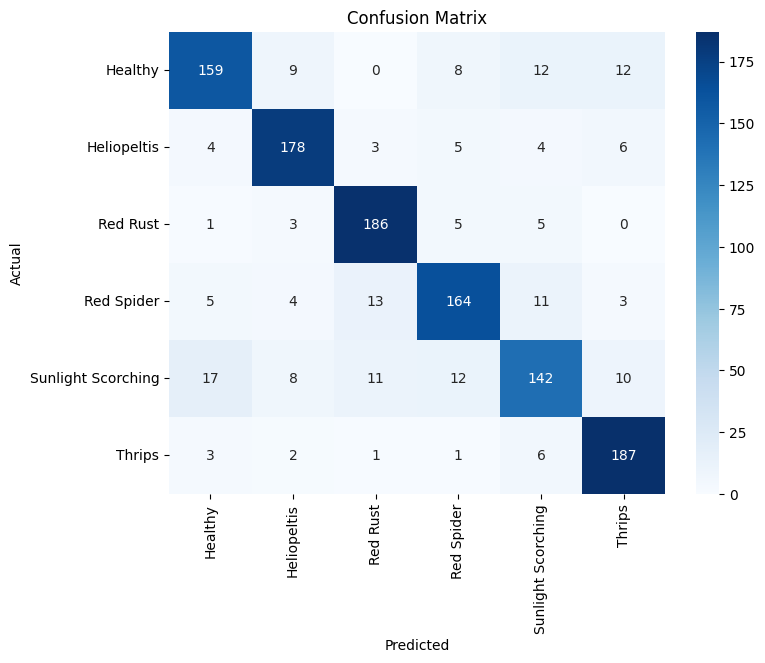

In [14]:

# 13. Visualization of the Confusion Matrix


cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


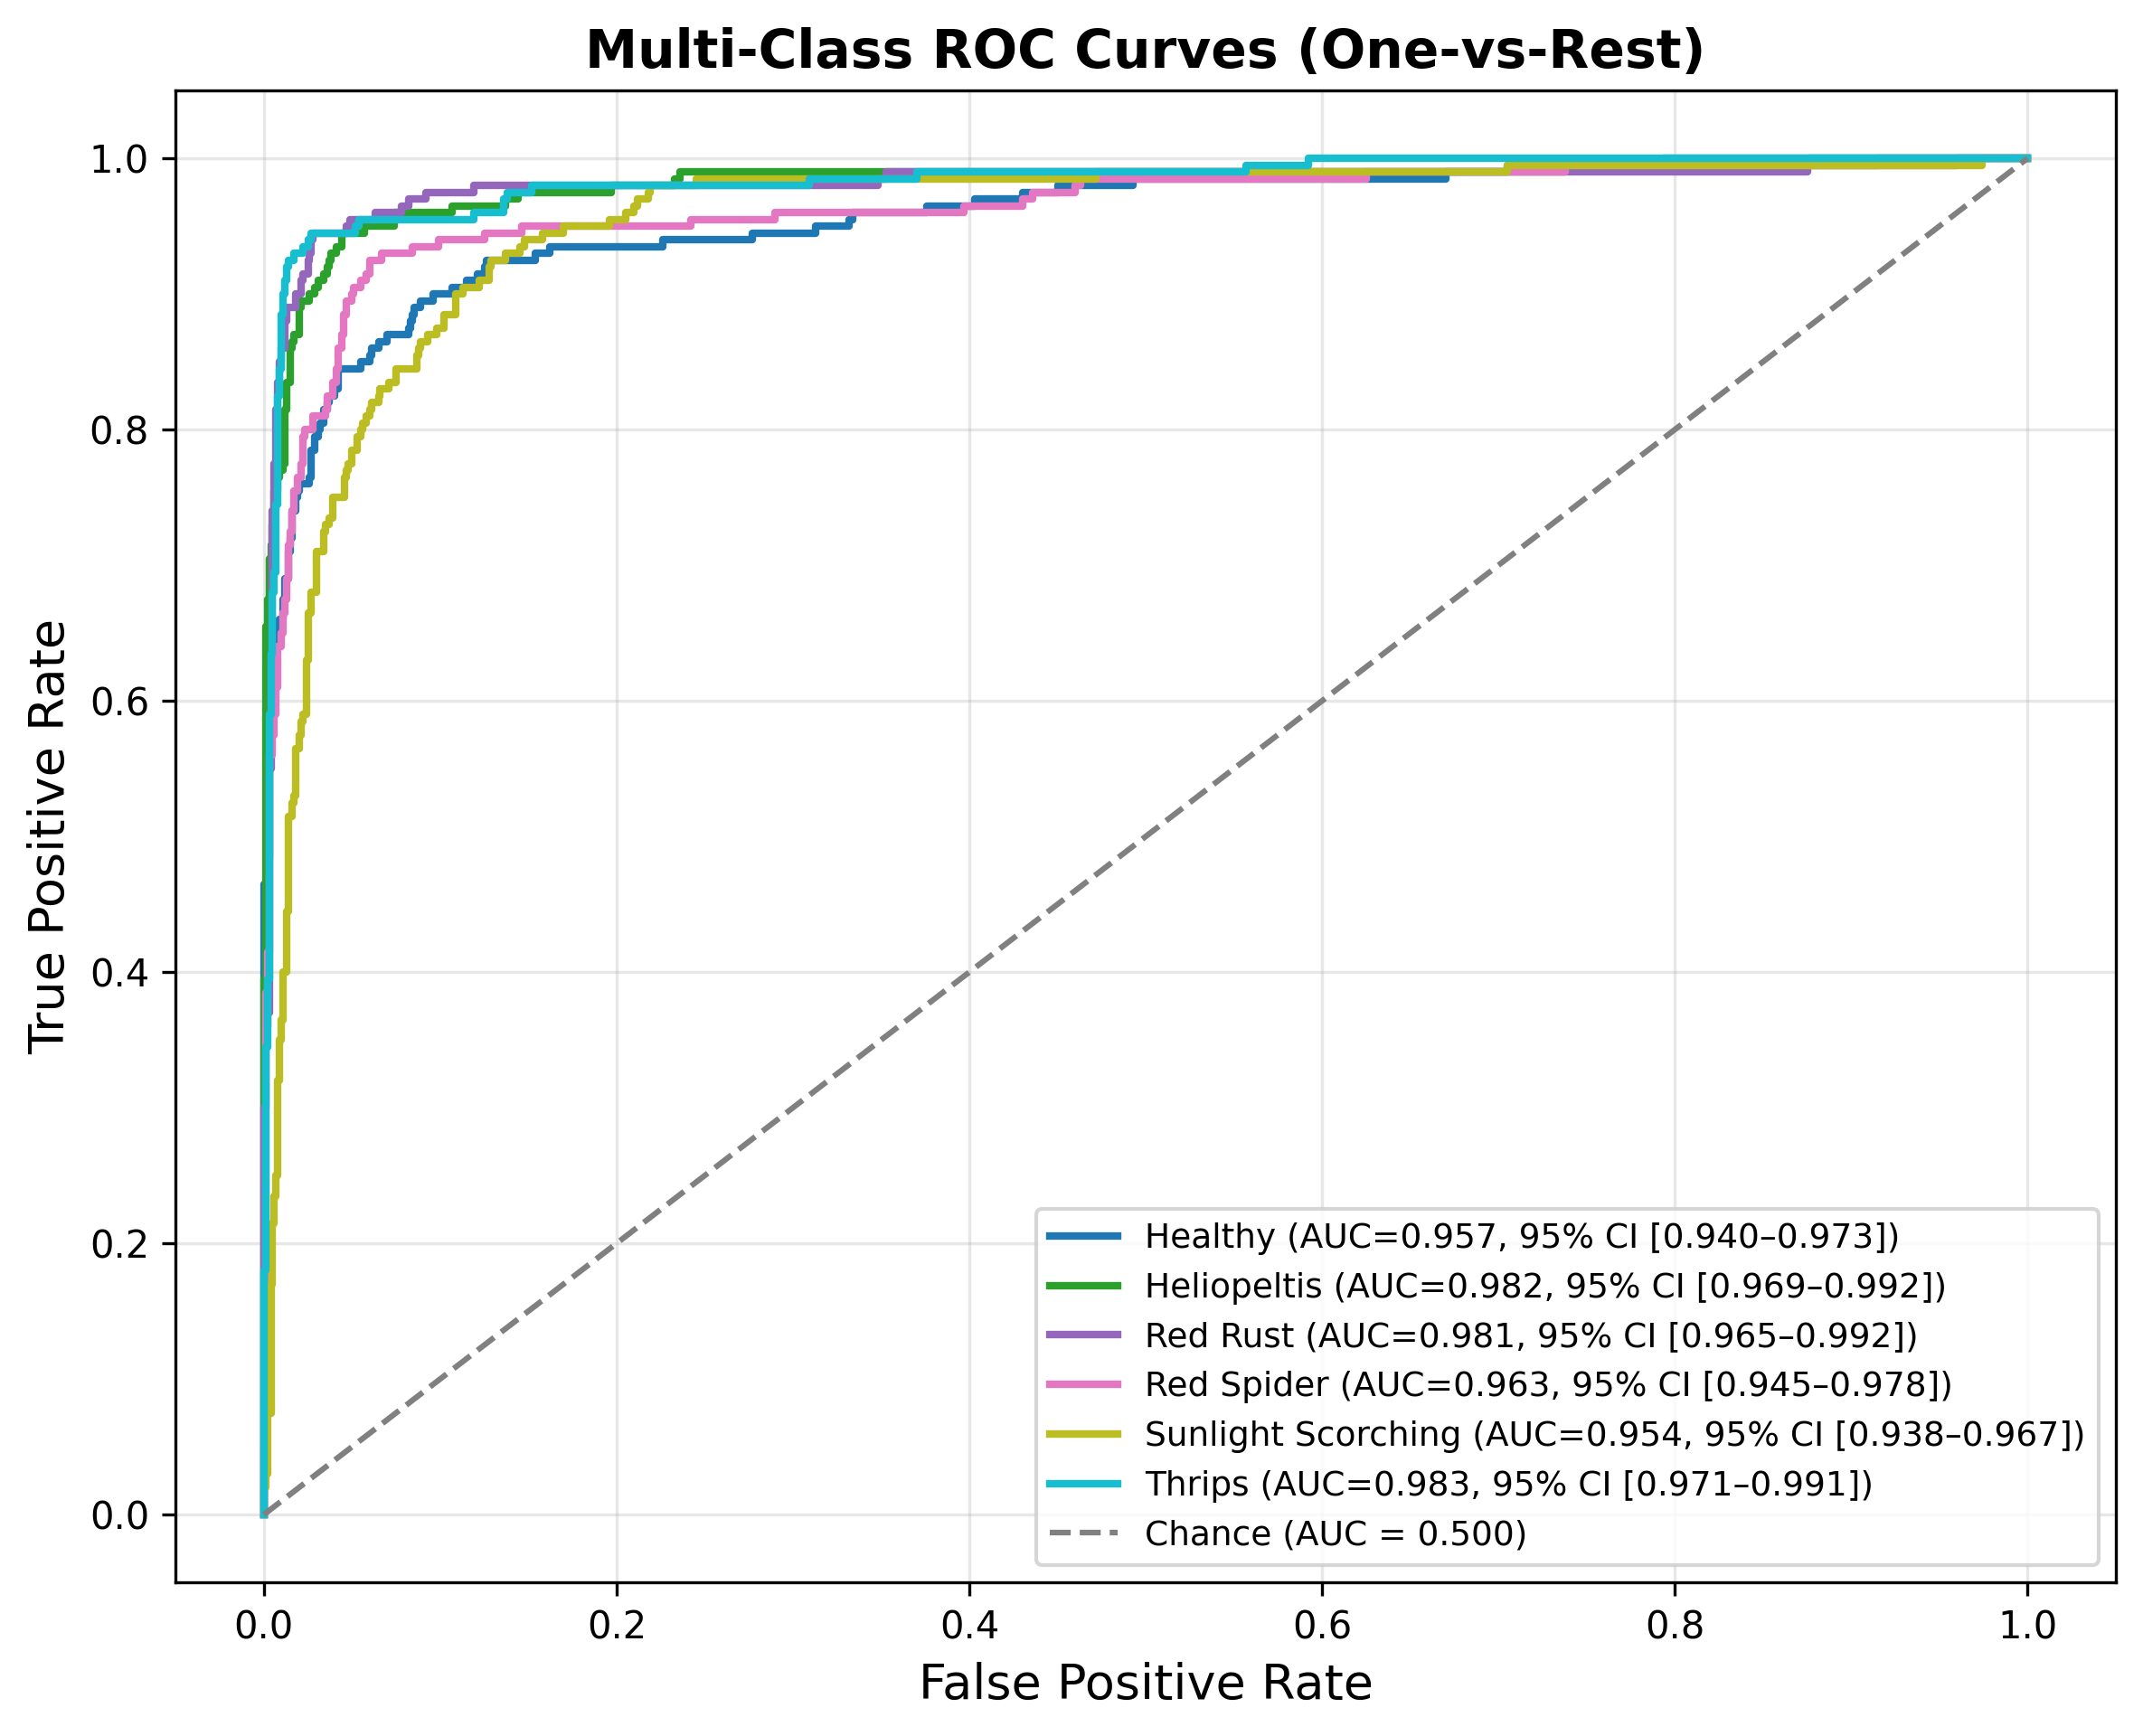

Class               AUC       95% CI
Healthy             0.957     [0.940, 0.973]
Heliopeltis         0.982     [0.969, 0.992]
Red Rust            0.981     [0.965, 0.992]
Red Spider          0.963     [0.945, 0.978]
Sunlight Scorching  0.954     [0.938, 0.967]
Thrips              0.983     [0.971, 0.991]


In [15]:
from sklearn.utils import resample
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

#  14. Visualization of the ROC Curve (One-vs-Rest) with 95% Bootstrap CI on AUC, 300 DPI export

y_test_bin = label_binarize(
    y_test,
    classes=np.arange(num_classes)
)

# ---- Bootstrap settings for 95% CI on AUC ----
n_bootstraps = 1000
rng_seed = 42
rng = np.random.RandomState(rng_seed)

fig, ax = plt.subplots(figsize=(8, 6.5), dpi=300)
colors = plt.cm.tab10(np.linspace(0, 1, num_classes))

auc_results = {}  # class_name -> (point_estimate, ci_low, ci_high)

for i in range(num_classes):

    y_true_i = y_test_bin[:, i]
    y_score_i = y_pred_prob[:, i]

    # Point-estimate ROC curve (full test set)
    fpr, tpr, _ = roc_curve(y_true_i, y_score_i)
    roc_auc = auc(fpr, tpr)

    # ---- Bootstrap resampling for 95% CI on AUC ----
    bootstrapped_aucs = []
    n_samples = len(y_true_i)
    for b in range(n_bootstraps):
        indices = rng.randint(0, n_samples, n_samples)
        if len(np.unique(y_true_i[indices])) < 2:
            continue  # skip resamples with only one class present
        fpr_b, tpr_b, _ = roc_curve(y_true_i[indices], y_score_i[indices])
        bootstrapped_aucs.append(auc(fpr_b, tpr_b))

    ci_lower = np.percentile(bootstrapped_aucs, 2.5)
    ci_upper = np.percentile(bootstrapped_aucs, 97.5)
    auc_results[class_names[i]] = (roc_auc, ci_lower, ci_upper)

    ax.plot(
        fpr, tpr, color=colors[i], linewidth=2,
        label=f"{class_names[i]} (AUC={roc_auc:.3f}, "
              f"95% CI [{ci_lower:.3f}\u2013{ci_upper:.3f}])"
    )

# Chance line (explicitly labeled)
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1.5, label='Chance (AUC = 0.500)')

ax.set_xlabel("False Positive Rate", fontsize=13)
ax.set_ylabel("True Positive Rate", fontsize=13)
ax.set_title("Multi-Class ROC Curves (One-vs-Rest)", fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=9, frameon=True)
ax.grid(alpha=0.3)
plt.tight_layout()

# ---- Save at true 300 DPI, plus vector formats for the manuscript ----
plt.savefig('roc_curve_highres.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig('roc_curve_highres.svg', bbox_inches='tight', facecolor='white')
plt.savefig('roc_curve_highres.pdf', bbox_inches='tight', facecolor='white')
plt.show()

# ---- Print a ready-to-paste AUC + 95% CI table for the manuscript ----
print(f"{'Class':<20}{'AUC':<10}{'95% CI'}")
for cls, (a, lo, hi) in auc_results.items():
    print(f"{cls:<20}{a:.3f}     [{lo:.3f}, {hi:.3f}]")

In [ ]:
# 15. MODEL SIZE & COMPUTATIONAL COST

import numpy as np

def count_params(keras_model):
    trainable = np.sum([np.prod(v.shape) for v in keras_model.trainable_weights])
    non_trainable = np.sum([np.prod(v.shape) for v in keras_model.non_trainable_weights])
    return int(trainable), int(non_trainable)

# --- Feature extractor (EfficientNetV2B3 backbone) ---
backbone_trainable, backbone_nontrainable = count_params(base_model)
backbone_total = backbone_trainable + backbone_nontrainable

# --- Classifier head (MLP trained on IBSSA-selected features) ---
head_trainable, head_nontrainable = count_params(model)
head_total = head_trainable + head_nontrainable

def params_to_mb(n_params, bytes_per_param=4):
    return n_params * bytes_per_param / (1024 ** 2)

print("=" * 60)
print("MODEL SIZE / COMPUTATIONAL COST SUMMARY")
print("=" * 60)
print(f"{'Component':<30}{'Params':>12}{'Size (MB)':>14}")
print(f"{'EfficientNetV2B3 (frozen)':<30}{backbone_total:>12,}{params_to_mb(backbone_total):>14.2f}")
print(f"{'MLP classifier head':<30}{head_total:>12,}{params_to_mb(head_total):>14.2f}")
print(f"{'Total (deployed pipeline)':<30}{backbone_total+head_total:>12,}{params_to_mb(backbone_total+head_total):>14.2f}")
print("-" * 60)
print(f"Input feature dimensionality (EfficientNetV2B3 pooled): {features.shape[1]}")
print(f"IBSSA-selected feature dimensionality:                  {X_train.shape[1]} "
      f"({100*X_train.shape[1]/features.shape[1]:.1f}% of full feature vector)")
print("=" * 60)

# --- FLOPs estimate for the MLP head (backbone FLOPs are the standard,
#     published EfficientNetV2B3 figure and should be cited from the
#     original paper rather than re-derived here) ---
def dense_flops(in_dim, out_dim):
    # 1 MAC (~2 FLOPs) per weight, plus bias add
    return 2 * in_dim * out_dim + out_dim

mlp_flops = 0
prev_dim = X_train.shape[1]
for layer in model.layers:
    if layer.__class__.__name__ == "Dense":
        out_dim = layer.units
        mlp_flops += dense_flops(prev_dim, out_dim)
        prev_dim = out_dim

print(f"\nEstimated MLP classifier head FLOPs (single forward pass): {mlp_flops:,} "
      f"(~{mlp_flops/1e6:.2f} MFLOPs)")
print("Note: EfficientNetV2B3 backbone FLOPs (~3.0 GFLOPs at 384x384, per the "
      "original EfficientNetV2 publication) should be reported alongside this "
      "figure for the full pipeline cost, since the backbone dominates total compute.")


MODEL SIZE / COMPUTATIONAL COST SUMMARY
Component                           Params     Size (MB)
EfficientNetV2B3 (frozen)       12,930,622         49.33
MLP classifier head                421,350          1.61
Total (deployed pipeline)       13,351,972         50.93
------------------------------------------------------------
Input feature dimensionality (EfficientNetV2B3 pooled): 1536
IBSSA-selected feature dimensionality:                  847 (55.1% of full feature vector)

Estimated MLP classifier head FLOPs (single forward pass): 836,646 (~0.84 MFLOPs)
Note: EfficientNetV2B3 backbone FLOPs (~3.0 GFLOPs at 384x384, per the original EfficientNetV2 publication) should be reported alongside this figure for the full pipeline cost, since the backbone dominates total compute.


In [ ]:
## 16. Training Time Instrumentation (run in place of original Cell 9)
# 9-REVISED. Training with wall-clock timing instrumentation


import time
from tensorflow.keras.callbacks import Callback

class EpochTimer(Callback):
    def __init__(self):
        super().__init__()
        self.epoch_times = []
    def on_epoch_begin(self, epoch, logs=None):
        self._t0 = time.time()
    def on_epoch_end(self, epoch, logs=None):
        self.epoch_times.append(time.time() - self._t0)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.1,
    patience=5,
    min_lr=0.000001,
    verbose=1
)

epoch_timer = EpochTimer()

train_start = time.time()
history = model.fit(
    X_train_augmented,
    y_train_cat_augmented,
    epochs=50,
    batch_size=32,
    validation_data=(X_val, y_val_cat),
    verbose=1,
    callbacks=[early_stopping, reduce_lr, epoch_timer]
)
train_total_time = time.time() - train_start

print(f"\nTotal training wall-clock time: {train_total_time:.2f} s "
      f"({train_total_time/60:.2f} min) over {len(epoch_timer.epoch_times)} epochs")
print(f"Mean epoch time: {np.mean(epoch_timer.epoch_times):.3f} s "
      f"(std: {np.std(epoch_timer.epoch_times):.3f} s)")


Epoch 1/50
240/240 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.9255 - loss: 0.8452 - val_accuracy: 0.8583 - val_loss: 1.1129 - learning_rate: 1.0000e-06
Epoch 2/50
240/240 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.9288 - loss: 0.8365 - val_accuracy: 0.8562 - val_loss: 1.1140 - learning_rate: 1.0000e-06
Epoch 3/50
240/240 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.9260 - loss: 0.8394 - val_accuracy: 0.8589 - val_loss: 1.1144 - learning_rate: 1.0000e-06
Epoch 4/50
240/240 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.9327 - loss: 0.8291 - val_accuracy: 0.8589 - val_loss: 1.1113 - learning_rate: 1.0000e-06
Epoch 5/50
240/240 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9322 - loss: 0.8300 - val_accuracy: 0.8589 - val_loss: 1.1119 - learning_rate: 1.0000e-06
Epoch 6/50
240/240 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - accuracy: 0.9303 - loss: 0.8297 - val_accuracy: 0.8583 - val_loss: 1.1123 - learning_rate: 1.0000e-06
Epoch 7/50
240/240 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - acc

In [ ]:
# 16. INFERENCE TIME

import time

# Warm-up run (first call includes graph tracing / XLA overhead - exclude from timing)
_ = model.predict(X_test[:min(32, len(X_test))], verbose=0)

# Full-batch inference timing
n_repeats = 20
batch_times = []
for _ in range(n_repeats):
    t0 = time.time()
    _ = model.predict(X_test, verbose=0)
    batch_times.append(time.time() - t0)

mean_batch_time = np.mean(batch_times)
per_sample_ms = 1000 * mean_batch_time / X_test.shape[0]

print("=" * 60)
print("INFERENCE TIME (MLP classifier head only, pre-extracted features)")
print("=" * 60)
print(f"Test set size:                 {X_test.shape[0]} samples")
print(f"Mean full-test-set inference:  {mean_batch_time*1000:.2f} ms  "
      f"(std: {np.std(batch_times)*1000:.2f} ms, n={n_repeats} runs)")
print(f"Mean per-sample inference:     {per_sample_ms:.3f} ms/image")
print(f"Throughput:                    {1000/per_sample_ms:.1f} images/sec")
print("-" * 60)
print("Note: this measures the trained MLP head only. End-to-end latency for a "
      "raw input image also includes one EfficientNetV2B3 forward pass "
      "(feature extraction), which should be timed separately and added if "
      "reporting full pipeline (image-in to prediction-out) latency.")

# --- Optional: end-to-end timing including the backbone, on a small sample ---
sample_batch = next(iter(
    ImageDataGenerator(preprocessing_function=preprocess_input).flow_from_directory(
        data_dir, target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE,
        class_mode='categorical', shuffle=False
    )
))[0]

_ = base_model.predict(sample_batch, verbose=0)  # warm-up
t0 = time.time()
feats_sample = base_model.predict(sample_batch, verbose=0)
backbone_time = time.time() - t0
print(f"\nEnd-to-end backbone forward pass (batch of {sample_batch.shape[0]}): "
      f"{backbone_time*1000:.2f} ms "
      f"({1000*backbone_time/sample_batch.shape[0]:.3f} ms/image)")


INFERENCE TIME (MLP classifier head only, pre-extracted features)
Test set size:                 1200 samples
Mean full-test-set inference:  217.26 ms  (std: 57.88 ms, n=20 runs)
Mean per-sample inference:     0.181 ms/image
Throughput:                    5523.3 images/sec
------------------------------------------------------------
Note: this measures the trained MLP head only. End-to-end latency for a raw input image also includes one EfficientNetV2B3 forward pass (feature extraction), which should be timed separately and added if reporting full pipeline (image-in to prediction-out) latency.
Found 6000 images belonging to 6 classes.

End-to-end backbone forward pass (batch of 32): 12574.52 ms (392.954 ms/image)


In [ ]:
# 17. COMPLETE PER-CLASS RESULTS (all six diseases)
# Combines precision/recall/F1/support from classification_report, specificity
# derived from the confusion matrix, and AUC + 95% bootstrap CI from Cell 14.

import pandas as pd

report_dict = classification_report(
    y_test, y_pred, target_names=class_names, output_dict=True
)

cm_full = confusion_matrix(y_test, y_pred)

rows = []
for i, cls in enumerate(class_names):
    tp = cm_full[i, i]
    fn = cm_full[i, :].sum() - tp
    fp = cm_full[:, i].sum() - tp
    tn = cm_full.sum() - tp - fn - fp
    specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    auc_val, ci_lo, ci_hi = auc_results.get(cls, (np.nan, np.nan, np.nan))

    rows.append({
        "Class": cls,
        "Precision": report_dict[cls]["precision"],
        "Recall (Sensitivity)": report_dict[cls]["recall"],
        "Specificity": specificity,
        "F1-score": report_dict[cls]["f1-score"],
        "Support": int(report_dict[cls]["support"]),
        "AUC": auc_val,
        "AUC 95% CI": f"[{ci_lo:.3f}, {ci_hi:.3f}]" if not np.isnan(ci_lo) else "-",
    })

per_class_df = pd.DataFrame(rows)

# Macro / weighted summary rows
summary_rows = pd.DataFrame([
    {"Class": "Macro avg",
     "Precision": report_dict["macro avg"]["precision"],
     "Recall (Sensitivity)": report_dict["macro avg"]["recall"],
     "Specificity": per_class_df["Specificity"].mean(),
     "F1-score": report_dict["macro avg"]["f1-score"],
     "Support": int(report_dict["macro avg"]["support"]),
     "AUC": per_class_df["AUC"].mean(),
     "AUC 95% CI": "-"},
    {"Class": "Weighted avg",
     "Precision": report_dict["weighted avg"]["precision"],
     "Recall (Sensitivity)": report_dict["weighted avg"]["recall"],
     "Specificity": np.average(per_class_df["Specificity"], weights=per_class_df["Support"]),
     "F1-score": report_dict["weighted avg"]["f1-score"],
     "Support": int(report_dict["weighted avg"]["support"]),
     "AUC": np.average(per_class_df["AUC"], weights=per_class_df["Support"]),
     "AUC 95% CI": "-"},
])

per_class_full = pd.concat([per_class_df, summary_rows], ignore_index=True)
per_class_full = per_class_full.round(4)

pd.set_option("display.width", 120)
print(per_class_full.to_string(index=False))

per_class_full.to_csv("per_class_results_all_six_diseases.csv", index=False)
print("\nSaved: per_class_results_all_six_diseases.csv")


             Class  Precision  Recall (Sensitivity)  Specificity  F1-score  Support    AUC     AUC 95% CI
           Healthy     0.8413                0.7950       0.9700    0.8175      200 0.9568 [0.940, 0.973]
       Heliopeltis     0.8725                0.8900       0.9740    0.8812      200 0.9816 [0.969, 0.992]
          Red Rust     0.8692                0.9300       0.9720    0.8986      200 0.9806 [0.965, 0.992]
        Red Spider     0.8410                0.8200       0.9690    0.8304      200 0.9630 [0.945, 0.978]
Sunlight Scorching     0.7889                0.7100       0.9620    0.7474      200 0.9542 [0.938, 0.967]
            Thrips     0.8578                0.9350       0.9690    0.8947      200 0.9831 [0.971, 0.991]
         Macro avg     0.8451                0.8467       0.9693    0.8450     1200 0.9699              -
      Weighted avg     0.8451                0.8467       0.9693    0.8450     1200 0.9699              -

Saved: per_class_results_all_six_diseases.csv

In [ ]:
# 18. STRATIFIED K-FOLD CROSS-VALIDATION
# # Re-running IBSSA feature selection independently inside every CV fold is the
# fully leakage-free approach, but IBSSA is a population-based metaheuristic
# (n_salps x max_iter x 3-fold internal RF-CV evaluations per candidate) and
# re-running it K times is computationally very expensive on the full dataset.

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
import time

RUN_NESTED_CV = False   # set True for the fully leakage-free (but slow) version
K_FOLDS = 5

X_all = np.vstack([X_train_raw, X_test_raw])   # full raw EfficientNetV2B3 features
y_all = np.concatenate([y_train, y_test])

skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=SEED)

def build_mlp(input_dim, n_classes):
    m = Sequential([
        Dense(384, activation='relu', input_shape=(input_dim,), kernel_regularizer=l2(0.001)),
        BatchNormalization(), Dropout(0.4),
        Dense(192, activation='relu', kernel_regularizer=l2(0.001)),
        BatchNormalization(), Dropout(0.4),
        Dense(96, activation='relu', kernel_regularizer=l2(0.001)),
        BatchNormalization(), Dropout(0.3),
        Dense(n_classes, activation='softmax')
    ])
    m.compile(optimizer=Adam(0.0001), loss='categorical_crossentropy', metrics=['accuracy'])
    return m

cv_records = []
fold_predictions = []  # (y_true, y_pred) per fold, for later McNemar / paired tests

t_cv_start = time.time()

for fold, (tr_idx, te_idx) in enumerate(skf.split(X_all, y_all), start=1):
    print(f"\n=== Fold {fold}/{K_FOLDS} ===")
    X_tr_raw, X_te_raw = X_all[tr_idx], X_all[te_idx]
    y_tr, y_te = y_all[tr_idx], y_all[te_idx]

    if RUN_NESTED_CV:
        fold_bssa = ImprovedBSSA(n_salps=20, max_iter=20, dim=X_tr_raw.shape[1], elite_ratio=0.1, verbose=False)
        fold_mask = fold_bssa.optimize(X_tr_raw, y_tr)
        fold_idx = np.where(fold_mask == 1)[0]
    else:
        fold_idx = selected_features_indices   # reuse the fixed IBSSA mask from Cell 5

    X_tr = X_tr_raw[:, fold_idx]
    X_te = X_te_raw[:, fold_idx]

    y_tr_cat = tf.keras.utils.to_categorical(y_tr, num_classes)
    y_te_cat = tf.keras.utils.to_categorical(y_te, num_classes)

    fold_model = build_mlp(X_tr.shape[1], num_classes)
    es = EarlyStopping(monitor='loss', patience=8, restore_best_weights=True)
    fold_model.fit(X_tr, y_tr_cat, epochs=50, batch_size=32, verbose=0, callbacks=[es])

    y_pred_fold_prob = fold_model.predict(X_te, verbose=0)
    y_pred_fold = np.argmax(y_pred_fold_prob, axis=1)

    acc = accuracy_score(y_te, y_pred_fold)
    f1m = f1_score(y_te, y_pred_fold, average='macro')
    prec = precision_score(y_te, y_pred_fold, average='macro', zero_division=0)
    rec = recall_score(y_te, y_pred_fold, average='macro', zero_division=0)

    cv_records.append({"Fold": fold, "Accuracy": acc, "Precision (macro)": prec,
                        "Recall (macro)": rec, "F1 (macro)": f1m,
                        "Features used": len(fold_idx)})
    fold_predictions.append((y_te, y_pred_fold))

    print(f"Fold {fold}: acc={acc:.4f}  f1_macro={f1m:.4f}")

print(f"\nTotal CV wall-clock time: {(time.time()-t_cv_start)/60:.2f} min")

cv_df = pd.DataFrame(cv_records)
print("\n" + "=" * 60)
print(f"{K_FOLDS}-FOLD STRATIFIED CROSS-VALIDATION RESULTS")
print("=" * 60)
print(cv_df.round(4).to_string(index=False))
print("-" * 60)
print(f"Mean Accuracy:        {cv_df['Accuracy'].mean():.4f} +/- {cv_df['Accuracy'].std():.4f}")
print(f"Mean F1 (macro):      {cv_df['F1 (macro)'].mean():.4f} +/- {cv_df['F1 (macro)'].std():.4f}")
print(f"Mean Precision:       {cv_df['Precision (macro)'].mean():.4f} +/- {cv_df['Precision (macro)'].std():.4f}")
print(f"Mean Recall:          {cv_df['Recall (macro)'].mean():.4f} +/- {cv_df['Recall (macro)'].std():.4f}")

cv_df.to_csv("cross_validation_results.csv", index=False)
print("\nSaved: cross_validation_results.csv")



=== Fold 1/5 ===


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Fold 1: acc=0.8483  f1_macro=0.8476

=== Fold 2/5 ===


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Fold 2: acc=0.8533  f1_macro=0.8524

=== Fold 3/5 ===


...

Fold 3: acc=0.8425  f1_macro=0.8412

=== Fold 4/5 ===


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Fold 4: acc=0.8333  f1_macro=0.8305

=== Fold 5/5 ===


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Fold 5: acc=0.8525  f1_macro=0.8511

Total CV wall-clock time: 8.13 min

5-FOLD STRATIFIED CROSS-VALIDATION RESULTS
 Fold  Accuracy  Precision (macro)  Recall (macro)  F1 (macro)  Features used
    1    0.8483             0.8497          0.8483      0.8476            847
    2    0.8533             0.8528          0.8533      0.8524            847
    3    0.8425             0.8428          0.8425      0.8412            847
    4    0.8333             0.8327          0.8333      0.8305            847
    5    0.8525             0.8525          0.8525      0.8511            847
------------------------------------------------------------
Mean Accuracy:        0.8460 +/- 0.0083
Mean F1 (macro):      0.8445 +/- 0.0090
Mean Precision:       0.8461 +/- 0.0085
Mean Recall:          0.8460 +/- 0.0083

Saved: cross_validation_results.csv


In [ ]:
# 19. STATISTICAL SIGNIFICANCE TESTING
# Two complementary tests are reported:
#  (a) Paired t-test / Wilcoxon signed-rank test across the K CV fold accuracies
#      of the PROPOSED model (IBSSA-selected features) versus a BASELINE model
#      (all EfficientNetV2B3 features, no IBSSA selection) trained/evaluated on
#      the SAME folds -- this is the correct way to compare two models' overall
#      performance across resampled data.
#  (b) McNemar's test on the single held-out test set, which compares the two
#      models' PER-SAMPLE correct/incorrect disagreement pattern -- the
#      standard test for comparing two classifiers on one fixed test set.

from scipy import stats
from statsmodels.stats.contingency_tables import mcnemar

# ---------- (a) Paired test across CV folds: proposed vs. all-features baseline ----------
print("=" * 70)
print("(a) Cross-validated comparison: IBSSA-selected features vs. ALL features")
print("=" * 70)

baseline_cv_records = []
for fold, (tr_idx, te_idx) in enumerate(skf.split(X_all, y_all), start=1):
    X_tr_raw, X_te_raw = X_all[tr_idx], X_all[te_idx]
    y_tr, y_te = y_all[tr_idx], y_all[te_idx]

    y_tr_cat = tf.keras.utils.to_categorical(y_tr, num_classes)

    baseline_model = build_mlp(X_tr_raw.shape[1], num_classes)
    es = EarlyStopping(monitor='loss', patience=8, restore_best_weights=True)
    baseline_model.fit(X_tr_raw, y_tr_cat, epochs=50, batch_size=32, verbose=0, callbacks=[es])

    y_pred_base = np.argmax(baseline_model.predict(X_te_raw, verbose=0), axis=1)
    baseline_cv_records.append(accuracy_score(y_te, y_pred_base))

proposed_acc = cv_df["Accuracy"].values
baseline_acc = np.array(baseline_cv_records)

print(f"Proposed (IBSSA) per-fold accuracy: {np.round(proposed_acc, 4)}")
print(f"Baseline (all features) per-fold accuracy: {np.round(baseline_acc, 4)}")

t_stat, p_ttest = stats.ttest_rel(proposed_acc, baseline_acc)
try:
    w_stat, p_wilcoxon = stats.wilcoxon(proposed_acc, baseline_acc)
except ValueError:
    w_stat, p_wilcoxon = np.nan, np.nan  # identical values / too few folds

print(f"\nPaired t-test:        t={t_stat:.4f},  p={p_ttest:.4g}")
print(f"Wilcoxon signed-rank: W={w_stat},  p={p_wilcoxon:.4g}" if not np.isnan(p_wilcoxon)
      else "Wilcoxon signed-rank: not computable (identical/insufficient pairs)")
alpha = 0.05
verdict = "statistically significant" if p_ttest < alpha else "not statistically significant"
print(f"=> Difference is {verdict} at alpha={alpha} (paired t-test).")

# ---------- (b) McNemar's test on the single held-out test set ----------
print("\n" + "=" * 70)
print("(b) McNemar's test on the held-out test set (Cell 5 split)")
print("=" * 70)

# Baseline model trained on the SAME train split but WITHOUT IBSSA feature selection
y_train_cat_full = tf.keras.utils.to_categorical(y_train, num_classes)
mcnemar_baseline = build_mlp(X_train_raw.shape[1], num_classes)
es = EarlyStopping(monitor='loss', patience=8, restore_best_weights=True)
mcnemar_baseline.fit(X_train_raw, y_train_cat_full, epochs=50, batch_size=32, verbose=0, callbacks=[es])
y_pred_mcnemar_base = np.argmax(mcnemar_baseline.predict(X_test_raw, verbose=0), axis=1)

correct_proposed = (y_pred == y_test)
correct_baseline = (y_pred_mcnemar_base == y_test)

n_both_correct = np.sum(correct_proposed & correct_baseline)
n_proposed_only = np.sum(correct_proposed & ~correct_baseline)
n_baseline_only = np.sum(~correct_proposed & correct_baseline)
n_both_wrong = np.sum(~correct_proposed & ~correct_baseline)

table = [[n_both_correct, n_proposed_only],
         [n_baseline_only, n_both_wrong]]

result = mcnemar(table, exact=(n_proposed_only + n_baseline_only) < 25, correction=True)
print(f"Contingency table [[both correct, proposed-only correct],"
      f" [baseline-only correct, both wrong]]:")
print(np.array(table))
print(f"\nMcNemar's test statistic = {result.statistic:.4f}, p-value = {result.pvalue:.4g}")
verdict = "statistically significant" if result.pvalue < alpha else "not statistically significant"
print(f"=> The disagreement pattern is {verdict} at alpha={alpha}.")
print("(A significant result means the two models' error patterns differ more than "
      "chance would predict on this test set -- i.e. IBSSA feature selection changes "
      "which samples are misclassified, not merely overall accuracy by chance.)")


(a) Cross-validated comparison: IBSSA-selected features vs. ALL features


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr

Proposed (IBSSA) per-fold accuracy: [0.8483 0.8533 0.8425 0.8333 0.8525]
Baseline (all features) per-fold accuracy: [0.8517 0.8592 0.8542 0.8425 0.8617]

Paired t-test:        t=-5.3736,  p=0.005793
Wilcoxon signed-rank: W=0.0,  p=0.0625
=> Difference is statistically significant at alpha=0.05 (paired t-test).

(b) McNemar's test on the held-out test set (Cell 5 split)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Contingency table [[both correct, proposed-only correct], [baseline-only correct, both wrong]]:
[[966  50]
 [ 61 123]]

McNemar's test statistic = 0.9009, p-value = 0.3425
=> The disagreement pattern is not statistically significant at alpha=0.05.
(A significant result means the two models' error patterns differ more than chance would predict on this test set -- i.e. IBSSA feature selection changes which samples are misclassified, not merely overall accuracy by chance.)


V1: Raw features, no IBSSA, no augmentation, no BN acc=0.8617  f1_macro=0.8601  params=683,238  train_time=116.3s


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


V2: + IBSSA feature selection (no augmentation, no BN) acc=0.8617  f1_macro=0.8599  params=418,662  train_time=87.1s


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


V3: + IBSSA + augmentation (no BN)            acc=0.8650  f1_macro=0.8639  params=418,662  train_time=138.1s
V4: Full proposed (IBSSA + augmentation + BN + Dropout) acc=0.8517  f1_macro=0.8498  params=420,006  (reused trained model)

ABLATION STUDY SUMMARY
                                                Variant  Accuracy  F1 (macro)  Trainable params  Train time (s)  Delta Accuracy vs V1
     V1: Raw features, no IBSSA, no augmentation, no BN    0.8617      0.8601            683238           116.3                0.0000
 V2: + IBSSA feature selection (no augmentation, no BN)    0.8617      0.8599            418662            87.1                0.0000
                     V3: + IBSSA + augmentation (no BN)    0.8650      0.8639            418662           138.1                0.0033
V4: Full proposed (IBSSA + augmentation + BN + Dropout)    0.8517      0.8498            420006             NaN               -0.0100

Saved: ablation_study_results.csv


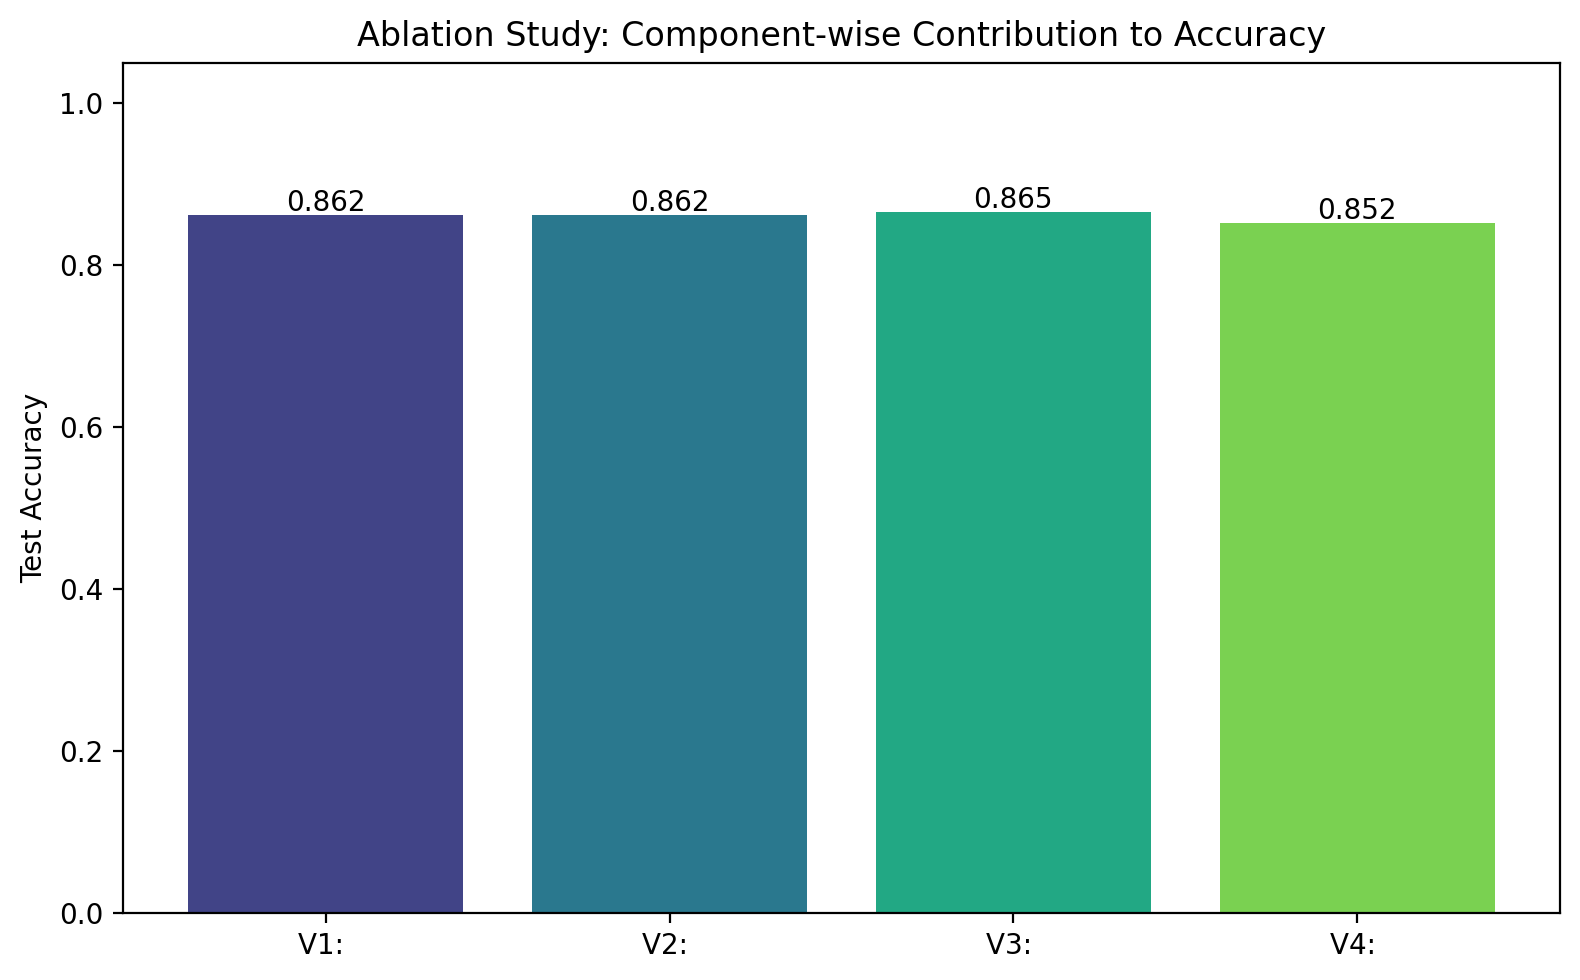

In [ ]:
# 20. ABLATION STUDY
# 
# Variants tested, each trained/evaluated on the SAME train/test split
# (Cell 5) for a fair, controlled comparison:
#   V1  Backbone features only, no IBSSA, no augmentation, plain MLP (no BN/Dropout tuning)
#   V2  + IBSSA feature selection (no augmentation, plain MLP)
#   V3  + IBSSA feature selection + augmentation (no BatchNorm)
#   V4  Full proposed model: IBSSA + augmentation + BatchNorm + Dropout (as in Cells 8-9)

import time

def build_plain_mlp(input_dim, n_classes, use_bn=True, dropout=(0.4, 0.4, 0.3)):
    layers = [Dense(384, activation='relu', input_shape=(input_dim,), kernel_regularizer=l2(0.001))]
    if use_bn: layers.append(BatchNormalization())
    layers.append(Dropout(dropout[0]))
    layers.append(Dense(192, activation='relu', kernel_regularizer=l2(0.001)))
    if use_bn: layers.append(BatchNormalization())
    layers.append(Dropout(dropout[1]))
    layers.append(Dense(96, activation='relu', kernel_regularizer=l2(0.001)))
    if use_bn: layers.append(BatchNormalization())
    layers.append(Dropout(dropout[2]))
    layers.append(Dense(n_classes, activation='softmax'))
    m = Sequential(layers)
    m.compile(optimizer=Adam(0.0001), loss='categorical_crossentropy', metrics=['accuracy'])
    return m

def evaluate_variant(name, X_tr, y_tr_cat, X_te, y_te, use_bn=True):
    t0 = time.time()
    m = build_plain_mlp(X_tr.shape[1], num_classes, use_bn=use_bn)
    es = EarlyStopping(monitor='loss', patience=8, restore_best_weights=True)
    m.fit(X_tr, y_tr_cat, epochs=50, batch_size=32, verbose=0, callbacks=[es])
    elapsed = time.time() - t0
    y_pred_v = np.argmax(m.predict(X_te, verbose=0), axis=1)
    acc = accuracy_score(y_te, y_pred_v)
    f1m = f1_score(y_te, y_pred_v, average='macro')
    n_params = int(np.sum([np.prod(v.shape) for v in m.trainable_weights]))
    print(f"{name:<45} acc={acc:.4f}  f1_macro={f1m:.4f}  "
          f"params={n_params:,}  train_time={elapsed:.1f}s")
    return {"Variant": name, "Accuracy": acc, "F1 (macro)": f1m,
            "Trainable params": n_params, "Train time (s)": round(elapsed, 1)}

ablation_results = []

y_train_cat_full = tf.keras.utils.to_categorical(y_train, num_classes)

# V1: raw features, no IBSSA, no augmentation, no BatchNorm
ablation_results.append(evaluate_variant(
    "V1: Raw features, no IBSSA, no augmentation, no BN",
    X_train_raw, y_train_cat_full, X_test_raw, y_test, use_bn=False
))

# V2: + IBSSA feature selection only
ablation_results.append(evaluate_variant(
    "V2: + IBSSA feature selection (no augmentation, no BN)",
    X_train, y_train_cat_full, X_test, y_test, use_bn=False
))

# V3: + IBSSA + augmentation (still no BatchNorm)
ablation_results.append(evaluate_variant(
    "V3: + IBSSA + augmentation (no BN)",
    X_train_augmented, y_train_cat_augmented, X_test, y_test, use_bn=False
))

# V4: Full proposed model (IBSSA + augmentation + BatchNorm + Dropout)
# Reuses the already-trained `model` from Cells 8-9 for consistency.
y_pred_v4 = np.argmax(model.predict(X_test, verbose=0), axis=1)
acc_v4 = accuracy_score(y_test, y_pred_v4)
f1_v4 = f1_score(y_test, y_pred_v4, average='macro')
n_params_v4 = int(np.sum([np.prod(v.shape) for v in model.trainable_weights]))
ablation_results.append({"Variant": "V4: Full proposed (IBSSA + augmentation + BN + Dropout)",
                          "Accuracy": acc_v4, "F1 (macro)": f1_v4,
                          "Trainable params": n_params_v4, "Train time (s)": np.nan})
print(f"{'V4: Full proposed (IBSSA + augmentation + BN + Dropout)':<45} "
      f"acc={acc_v4:.4f}  f1_macro={f1_v4:.4f}  params={n_params_v4:,}  (reused trained model)")

ablation_df = pd.DataFrame(ablation_results)
ablation_df["Delta Accuracy vs V1"] = ablation_df["Accuracy"] - ablation_df["Accuracy"].iloc[0]

print("\n" + "=" * 80)
print("ABLATION STUDY SUMMARY")
print("=" * 80)
print(ablation_df.round(4).to_string(index=False))
ablation_df.to_csv("ablation_study_results.csv", index=False)
print("\nSaved: ablation_study_results.csv")

# --- Bar chart of the ablation progression ---
fig, ax = plt.subplots(figsize=(8, 5), dpi=200)
bars = ax.bar(ablation_df["Variant"].str[:4], ablation_df["Accuracy"], color=plt.cm.viridis(np.linspace(0.2, 0.8, 4)))
for b, acc in zip(bars, ablation_df["Accuracy"]):
    ax.text(b.get_x() + b.get_width()/2, acc + 0.005, f"{acc:.3f}", ha='center', fontsize=10)
ax.set_ylabel("Test Accuracy")
ax.set_title("Ablation Study: Component-wise Contribution to Accuracy")
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig("ablation_study_chart.png", dpi=300, bbox_inches='tight')
plt.show()
